# Deep Armocromia — Audit Label Otomatis (setelah E14)

**Latar belakang.** Akurasi sub-season di official test berhenti di sekitar 35% sejak E12 (E12 35,42%, E13 34,98%, E14 34,65%), padahal arsitekturnya berganti-ganti. Ketiganya gagal di pasangan kelas yang sama (autunno_deep ↔ inverno_deep, inverno_cool ↔ inverno_deep, estate_light ↔ primavera_light). Notebook ini menguji secara otomatis, tanpa penilaian manusia, apakah plateau itu disebabkan oleh **label** atau oleh **model**.

**Empat pemeriksaan:**

| Bagian | Pertanyaan | Cara |
|---|---|---|
| A. Konsistensi label | Apakah foto orang yang sama / foto hampir identik diberi label yang sama? | Grup nama file (non-CelebA) dan pasangan near-duplicate embedding |
| B. Label yang dicurigai | Gambar mana yang labelnya bertentangan kuat dengan isi gambarnya? | *Confident learning* (Northcutt dkk., 2021) di atas prediksi out-of-fold model `emb_color_lr` |
| C. Keterpisahan kelas | Apakah tiap pasangan sub-season memang bisa dibedakan dari gambar? | AUROC biner per pasangan kelas (66 pasangan), fitur Lab saja dan embedding + Lab |
| D. Dampak ke official test | Apakah membuang label yang dicurigai dari data latih menaikkan akurasi official test? | Latih ulang `emb_color_lr` dengan 0–20% data latih paling mencurigakan dibuang |

Prediksi yang dipakai adalah `emb_color_lr` (komponen ringan E14, official test 31,8%), bukan ensemble E14, karena audit butuh probabilitas lengkap untuk **setiap** gambar latih secara out-of-fold. Bila output E14 ter-attach, prediksi ensemble E14 di official test ikut dipakai sebagai pembanding.

**Syarat Kaggle:** GPU T4 (hanya perlu bila output E14 tidak ditemukan), Internet ON, dataset Deep Armocromia ter-attach, Secret `DEEP_ARMO_PASSWORD` (dan `HF_TOKEN` bila menghitung ulang).
**Opsional tapi disarankan:** *Add Input* → *Your Work* → notebook E14 (versi yang sudah Save & Run). Notebook ini mencari `region_features.npz`, `frozen_embeddings.npz`, dan `E14_test_predictions.csv` di `/kaggle/input`. Bila ketemu, waktu jalan ±10 menit; bila tidak, ±30 menit.

Label official test **tidak** dipakai untuk melatih atau memilih apa pun. Di bagian D, label test hanya dipakai untuk mengukur akurasi.

In [1]:
# ============================================================
# 0. CONFIG
# ============================================================
EXPERIMENT_ID = "AUDIT_LABEL_AFTER_E14"
SEED = 42
NUM_CLASSES = 12
NUM_SEASONS = 4
SMOKE_TEST = False              # tidak dipakai di audit; dipertahankan agar sel yang disalin dari E14 tetap jalan

DATA_PASSWORD_SECRET_NAME = "DEEP_ARMO_PASSWORD"
HF_TOKEN_SECRET_NAME = "HF_TOKEN"

FROZEN_HF_ID = "facebook/dinov3-vits16-pretrain-lvd1689m"   # sama dengan E12-E14
EMB_IMG_SIZE = 224
EXTRA_MEAN_LAYERS = [4, 8]
PARSER_HF_ID = "jonathandinu/face-parsing"
PARSE_SIZE = 512
CACHE_SIZE = 256
MASK_THRESH = 8 / 255
PARSE_BATCH = 16
USE_BINARY_MASK = True
NUM_WORKERS = 2

N_FOLDS = 5
DUP_THR = 0.90                   # sama dengan E12-E14
DUP_LEVELS = [0.90, 0.93, 0.95, 0.97]
GENERIC_NAMES = {"images", "image", "img", "download", "downloads", "unnamed", "untitled", "photo", "foto",
                 "picture", "pic", "screenshot", "file", "immagine", "senza titolo"}

C_LR = 1e-3                      # C terpilih untuk emb_color_lr di E14
C_LAB = 0.1                      # C untuk LR biner fitur Lab saja (bagian C)
FOCUS_PAIRS = [("autunno_deep", "inverno_deep"), ("inverno_cool", "inverno_deep"),
               ("estate_light", "primavera_light"), ("autunno_warm", "primavera_warm"),
               ("estate_soft", "estate_cool"), ("estate_light", "estate_soft")]
DROP_FRACS = [0.0, 0.05, 0.10, 0.15, 0.20]
N_BOOT = 2000

EXPECTED_ROWS = (4920, 4008, 912)
REFERENCE_TEST_ACC = {"E12": 0.3542, "E13": 0.3498, "E14": 0.3465, "E14 emb_color_lr": 0.3180}

from pathlib import Path
RESULT_DIR = Path("/kaggle/working/AUDIT")
RESULT_DIR.mkdir(parents=True, exist_ok=True)
print("Experiment:", EXPERIMENT_ID, "| hasil:", RESULT_DIR)

Experiment: AUDIT_LABEL_AFTER_E14 | hasil: /kaggle/working/AUDIT


In [2]:
# ============================================================
# 1. IMPORTS
# ============================================================
import os, re, gc, json, time, shutil, hashlib, itertools, subprocess, warnings, random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm

from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
random.seed(SEED); np.random.seed(SEED)

## 2. Dataset dan anotasi (sama dengan E14)

In [3]:
# ============================================================
# 2.1 DETEKSI DATASET
# ============================================================
KAGGLE_INPUT = Path("/kaggle/input")
WORK_PREPARED_ROOT = Path("/kaggle/working/deep_armocromia_prepared")

prepared, source = [], []
for ann in KAGGLE_INPUT.rglob("annotations.csv"):
    root = ann.parent
    if (root / "RGB-M").is_dir():
        prepared.append((root, ann))
    if (root / "RGB-M.zip").is_file():
        source.append((root, ann, root / "RGB-M.zip"))

if prepared:
    MODE = "PREPARED_INPUT"
    DATA_ROOT, ANNOTATION_PATH = prepared[0]
elif source:
    MODE = "ENCRYPTED_SOURCE"
    _, ANNOTATION_PATH, _ = source[0]
    DATA_ROOT = WORK_PREPARED_ROOT
else:
    raise FileNotFoundError("annotations.csv + RGB-M/ atau RGB-M.zip tidak ditemukan di /kaggle/input.")
print("MODE:", MODE, "| ANNOTATION:", ANNOTATION_PATH)

MODE: ENCRYPTED_SOURCE | ANNOTATION: /kaggle/input/datasets/fatihitsbatulhaq/deep-armocromia/Deep Armocromia/release/annotations.csv


In [4]:
# ============================================================
# 2.2 LOAD ANNOTATIONS
# ============================================================
df = pd.read_csv(ANNOTATION_PATH)
SEASON_COL, SUBCLASS_COL, PARTITION_COL, MASKED_PATH_COL = "class", "sub_class", "partition", "path_rgb_masked"
missing = [c for c in [SEASON_COL, SUBCLASS_COL, PARTITION_COL, MASKED_PATH_COL, "celeba"] if c not in df.columns]
assert not missing, f"Missing columns: {missing}"

for col in [SEASON_COL, SUBCLASS_COL, PARTITION_COL]:
    df[col] = df[col].astype(str).str.strip().str.lower()
if df["celeba"].dtype != bool:
    mapped = df["celeba"].astype(str).str.strip().str.lower().map({"true": True, "1": True, "false": False, "0": False})
    assert mapped.notna().all(), "Kolom celeba punya nilai tak dikenal."
    df["celeba"] = mapped.astype(bool)
df["joint_label"] = df[SEASON_COL] + "_" + df[SUBCLASS_COL]

if EXPECTED_ROWS:
    assert len(df) == EXPECTED_ROWS[0], f"Jumlah baris {len(df)} != {EXPECTED_ROWS[0]}"
assert df[SEASON_COL].nunique() == NUM_SEASONS and df["joint_label"].nunique() == NUM_CLASSES

if SMOKE_TEST:
    tr_s = df[df[PARTITION_COL] == "train"].groupby("joint_label").sample(n=30, random_state=SEED)
    te_s = df[df[PARTITION_COL] == "test"].groupby("joint_label").sample(n=10, random_state=SEED)
    df = pd.concat([tr_s, te_s]).sort_index()
    print("SMOKE_TEST: memakai subset", len(df), "gambar.")

df = df.reset_index(drop=True)
display(pd.crosstab(df[PARTITION_COL], df["celeba"]))
MASK_COL = "path_mask" if "path_mask" in df.columns else None

celeba,False,True
partition,,
test,0,912
train,1939,2069


In [5]:
# ============================================================
# 2.3 SIAPKAN FOLDER GAMBAR: RGB-M (wajib) dan mask biner (opsional)
# ============================================================
SRC_ROOT = ANNOTATION_PATH.parent
WORK_PREPARED_ROOT.mkdir(parents=True, exist_ok=True)
_PW = {}

def get_password():
    if "v" not in _PW:
        from kaggle_secrets import UserSecretsClient
        try:
            _PW["v"] = UserSecretsClient().get_secret(DATA_PASSWORD_SECRET_NAME)
        except Exception as e:
            raise RuntimeError(f"Secret '{DATA_PASSWORD_SECRET_NAME}' belum tersedia / belum di-enable.") from e
        assert _PW["v"]
    return _PW["v"]

def norm_rel(rel):
    return Path(str(rel).replace("\\", "/").strip().lstrip("/"))

def resolve_in(rel, top):
    p = norm_rel(rel)
    for root in (SRC_ROOT, WORK_PREPARED_ROOT):
        for c in (root / p, root / top / p):
            if c.is_file():
                return c
    return None

def resolve_column(col):
    top = norm_rel(df[col].iloc[0]).parts[0]
    return df[col].apply(lambda r: resolve_in(r, top)), top

def extract_zip(zip_path):
    pw = get_password()
    unzip_path = shutil.which("unzip")
    if unzip_path:
        r = subprocess.run([unzip_path, "-n", "-P", pw, str(zip_path), "-d", str(WORK_PREPARED_ROOT)],
                           stdout=subprocess.DEVNULL, stderr=subprocess.PIPE, text=True)
        if r.returncode not in (0, 1):
            raise RuntimeError(r.stderr[-3000:])
    else:
        import zipfile
        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall(WORK_PREPARED_ROOT, pwd=pw.encode("utf-8"))

def ensure_column(col, required):
    paths, top = resolve_column(col)
    if not paths.notna().all():
        zips = [SRC_ROOT / f"{top}.zip"] + sorted(KAGGLE_INPUT.rglob(f"{top}.zip"))
        zips = [z for z in zips if z.is_file()]
        if zips:
            try:
                print(f"Mengekstrak {zips[0].name} ...")
                extract_zip(zips[0])
                paths, _ = resolve_column(col)
            except Exception as e:
                if required:
                    raise
                print(f"CATATAN: gagal mengekstrak {zips[0].name}: {str(e)[:300]}")
    if paths.notna().all():
        return paths
    msg = f"Kolom '{col}': {int(paths.isna().sum())} dari {len(paths)} file tidak ditemukan."
    if required:
        raise FileNotFoundError(msg)
    print("CATATAN:", msg, "-> fitur ini dimatikan.")
    return None

df["resolved_path"] = ensure_column(MASKED_PATH_COL, required=True)
df["mask_path"] = None
if USE_BINARY_MASK and MASK_COL:
    _r = ensure_column(MASK_COL, required=False)
    if _r is not None:
        df["mask_path"] = _r
_PW.clear()
HAS_MASK = bool(df["mask_path"].notna().all())
print(f"RGB-M: {len(df)} file | mask biner: {'ADA' if HAS_MASK else 'tidak dipakai'}")

Mengekstrak RGB-M.zip ...
Mengekstrak BM.zip ...
RGB-M: 4920 file | mask biner: ADA


In [6]:
# ============================================================
# 2.4 PATH, MD5, LABEL, SPLIT RESMI
# ============================================================
def md5_file(path, chunk=1024 * 1024):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

df["md5"] = df["resolved_path"].apply(md5_file)
assert (df.groupby("md5")[PARTITION_COL].nunique() > 1).sum() == 0, "Ada gambar identik di train dan test."
md5_all = df["md5"].to_numpy().astype(str)
N_ALL = len(df)

class_names = sorted(df["joint_label"].unique().tolist())
class2idx = {n: i for i, n in enumerate(class_names)}
idx2class = {i: n for n, i in class2idx.items()}
season_names = sorted(df[SEASON_COL].unique().tolist())
char_names = sorted(df[SUBCLASS_COL].unique().tolist())
season2idx = {n: i for i, n in enumerate(season_names)}
char2idx = {n: i for i, n in enumerate(char_names)}
WARM_SEASONS = {"autunno", "primavera"}

season_of = np.array([season2idx[n.split("_", 1)[0]] for n in class_names])
char_of = np.array([char2idx[n.split("_", 1)[1]] for n in class_names])
warm_of = np.array([int(n.split("_", 1)[0] in WARM_SEASONS) for n in class_names])
NUM_CHARS = len(char_names)

df["target"] = df["joint_label"].map(class2idx).astype(int)
ALL_Y = {"y12": df["target"].to_numpy(), "yS": season_of[df["target"].to_numpy()],
         "yC": char_of[df["target"].to_numpy()], "yU": warm_of[df["target"].to_numpy()]}

is_train = (df[PARTITION_COL] == "train").to_numpy()
train_rows, test_rows = np.where(is_train)[0], np.where(~is_train)[0]
if EXPECTED_ROWS and not SMOKE_TEST:
    assert len(train_rows) == EXPECTED_ROWS[1] and len(test_rows) == EXPECTED_ROWS[2]
yte = ALL_Y["y12"][test_rows]
print("Kelas        :", class_names)
print("Train / test :", len(train_rows), "/", len(test_rows))

Kelas        : ['autunno_deep', 'autunno_soft', 'autunno_warm', 'estate_cool', 'estate_light', 'estate_soft', 'inverno_bright', 'inverno_cool', 'inverno_deep', 'primavera_bright', 'primavera_light', 'primavera_warm']
Train / test : 4008 / 912


In [7]:
# ============================================================
# 3.1 FUNGSI WARNA
# ============================================================
def rgb2lab_np(rgb):
    rgb = np.asarray(rgb, dtype=np.float64)
    lin = np.where(rgb > 0.04045, ((rgb + 0.055) / 1.055) ** 2.4, rgb / 12.92)
    M = np.array([[0.4124564, 0.3575761, 0.1804375],
                  [0.2126729, 0.7151522, 0.0721750],
                  [0.0193339, 0.1191920, 0.9503041]])
    xyz = (lin @ M.T) / np.array([0.95047, 1.0, 1.08883])
    eps, kappa = 216 / 24389, 24389 / 27
    f = np.where(xyz > eps, np.cbrt(xyz), (kappa * xyz + 16) / 116)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], axis=-1)

REGION_PARTS = {
    "skin": ["skin", "nose"],
    "hair": ["hair"],
    "eye":  ["l_eye", "r_eye"],
    "lip":  ["u_lip", "l_lip"],
    "brow": ["l_brow", "r_brow"],
}
REGION_MIN_PIX = {"skin": 400, "hair": 300, "eye": 20, "lip": 40, "brow": 30}
BASE_STATS = ["L", "a", "b", "L_p25", "L_p75", "a_p25", "a_p75", "b_p25", "b_p75", "L_std", "chroma", "hue"]
SKIN_EXTRA = ["a_std", "b_std", "L_p10", "L_p90", "ita"]
CONTRASTS = ["dL_skin_hair", "dE_skin_hair", "db_hair_skin", "da_hair_skin", "dL_skin_eye", "dE_skin_eye",
             "dE_skin_lip", "da_lip_skin", "db_lip_skin", "dL_skin_brow", "dL_hair_eye", "dC_hair_skin", "L_range"]

REGION_COLS = []
for _r in REGION_PARTS:
    REGION_COLS += [f"{_r}_{s}" for s in BASE_STATS]
REGION_COLS += [f"skin_{s}" for s in SKIN_EXTRA]
REGION_COLS += [f"frac_{r}" for r in REGION_PARTS] + ["frac_glasses"]
REGION_COLS += CONTRASTS + ["all_L", "all_a", "all_b"]
COL_IX = {c: i for i, c in enumerate(REGION_COLS)}

def region_color_features(img_u8, label_map, region_ids, glasses_ids=(), valid=None):
    out = np.full(len(REGION_COLS), np.nan)
    if valid is None:
        valid = img_u8.max(axis=2) > int(MASK_THRESH * 255)
    n_valid = int(valid.sum())
    if n_valid < 200:
        return out
    lab_all = rgb2lab_np(img_u8[valid].astype(np.float32) / 255.0)
    out[[COL_IX["all_L"], COL_IX["all_a"], COL_IX["all_b"]]] = np.median(lab_all, axis=0)
    lm_valid = label_map[valid]

    med, chroma = {}, {}
    for r, ids in region_ids.items():
        m = np.isin(lm_valid, ids)
        n = int(m.sum())
        out[COL_IX[f"frac_{r}"]] = n / n_valid
        if n < REGION_MIN_PIX[r]:
            continue
        lab = lab_all[m]
        if r == "skin":                                   # buang bayangan dan highlight ekstrem
            lo, hi = np.percentile(lab[:, 0], [10, 90])
            keep = (lab[:, 0] >= lo) & (lab[:, 0] <= hi)
            if keep.sum() >= REGION_MIN_PIX[r] // 2:
                lab = lab[keep]
        md = np.median(lab, axis=0)
        med[r] = md
        p25, p75 = np.percentile(lab, [25, 75], axis=0)
        out[COL_IX[f"{r}_L"]], out[COL_IX[f"{r}_a"]], out[COL_IX[f"{r}_b"]] = md
        for ci, ch in enumerate("Lab"):
            out[COL_IX[f"{r}_{ch}_p25"]], out[COL_IX[f"{r}_{ch}_p75"]] = p25[ci], p75[ci]
        out[COL_IX[f"{r}_L_std"]] = lab[:, 0].std()
        chroma[r] = float(np.median(np.hypot(lab[:, 1], lab[:, 2])))
        out[COL_IX[f"{r}_chroma"]] = chroma[r]
        out[COL_IX[f"{r}_hue"]] = np.degrees(np.arctan2(md[2], md[1]))
        if r == "skin":
            out[COL_IX["skin_a_std"]], out[COL_IX["skin_b_std"]] = lab[:, 1].std(), lab[:, 2].std()
            out[COL_IX["skin_L_p10"]], out[COL_IX["skin_L_p90"]] = np.percentile(lab[:, 0], [10, 90])
            out[COL_IX["skin_ita"]] = np.degrees(np.arctan2(md[0] - 50.0, md[2]))
    out[COL_IX["frac_glasses"]] = float(np.isin(lm_valid, list(glasses_ids)).sum()) / n_valid if len(glasses_ids) else 0.0

    def dE(x, y):
        return float(np.linalg.norm(med[x] - med[y]))
    if "skin" in med and "hair" in med:
        out[COL_IX["dL_skin_hair"]] = med["skin"][0] - med["hair"][0]
        out[COL_IX["dE_skin_hair"]] = dE("skin", "hair")
        out[COL_IX["db_hair_skin"]] = med["hair"][2] - med["skin"][2]
        out[COL_IX["da_hair_skin"]] = med["hair"][1] - med["skin"][1]
        out[COL_IX["dC_hair_skin"]] = chroma["hair"] - chroma["skin"]
    if "skin" in med and "eye" in med:
        out[COL_IX["dL_skin_eye"]] = med["skin"][0] - med["eye"][0]
        out[COL_IX["dE_skin_eye"]] = dE("skin", "eye")
    if "skin" in med and "lip" in med:
        out[COL_IX["dE_skin_lip"]] = dE("skin", "lip")
        out[COL_IX["da_lip_skin"]] = med["lip"][1] - med["skin"][1]
        out[COL_IX["db_lip_skin"]] = med["lip"][2] - med["skin"][2]
    if "skin" in med and "brow" in med:
        out[COL_IX["dL_skin_brow"]] = med["skin"][0] - med["brow"][0]
    if "hair" in med and "eye" in med:
        out[COL_IX["dL_hair_eye"]] = med["hair"][0] - med["eye"][0]
    Ls = [med[r][0] for r in ("skin", "hair", "eye") if r in med]
    if len(Ls) >= 2:
        out[COL_IX["L_range"]] = max(Ls) - min(Ls)
    return out

def load_squares(path, mask_path=None):
    # Letterbox ke persegi. Keluaran: RGB-M (PARSE_SIZE), RGB-M (CACHE_SIZE), piksel valid (PARSE_SIZE, bool)
    with Image.open(path) as im:
        im = im.convert("RGB")
        base_size = im.size
        sq = ImageOps.pad(im, (PARSE_SIZE, PARSE_SIZE), method=Image.BILINEAR, color=(0, 0, 0))
    big = np.array(sq, dtype=np.uint8)
    small = np.array(sq.resize((CACHE_SIZE, CACHE_SIZE), Image.BILINEAR), dtype=np.uint8)
    valid = big.max(axis=2) > int(MASK_THRESH * 255)
    if mask_path is not None:
        with Image.open(mask_path) as mk:
            mk = mk.convert("L")
            if mk.size != base_size:
                mk = mk.resize(base_size, Image.NEAREST)
            arr = np.array(ImageOps.pad(mk, (PARSE_SIZE, PARSE_SIZE), method=Image.NEAREST, color=0))
        valid = arr > (arr.max() / 2.0) if arr.max() > 0 else valid
    return big, small, valid

print(len(REGION_COLS), "fitur Lab per region (E12: 53).")

87 fitur Lab per region (E12: 53).


In [8]:
# ============================================================
# 3. AMBIL FITUR DARI OUTPUT E14 (bila ter-attach)
# ============================================================
y_all = df["target"].to_numpy()
rel_paths = df[MASKED_PATH_COL].map(lambda r: str(r).replace("\\", "/").strip().lstrip("/")).to_numpy()
REG = EMB = None
E14_PRED = None

for f in sorted(KAGGLE_INPUT.rglob("region_features.npz")):
    z = np.load(f, allow_pickle=False)
    if z["reg"].shape == (N_ALL, len(REGION_COLS)) and np.array_equal(z["md5"].astype(str), md5_all):
        REG = z["reg"]
        print("Fitur Lab per region diambil dari:", f)
        break

for f in sorted(KAGGLE_INPUT.rglob("frozen_embeddings.npz")):
    z = np.load(f, allow_pickle=False)
    meta = json.loads(str(z["meta"]))
    if meta.get("model") == FROZEN_HF_ID and np.array_equal(z["md5"].astype(str), md5_all):
        EMB = {k: z[k] for k in z.files if k not in ("md5", "meta")}
        print("Embedding frozen diambil dari:", f)
        break

for f in sorted(KAGGLE_INPUT.rglob("E14_test_predictions.csv")):
    pr = pd.read_csv(f)
    key = pr["path"].astype(str).str.replace("\\", "/", regex=False).str.extract(r"(RGB-M/.*)$")[0]
    m = dict(zip(key, pr["pred"]))
    pred = [m.get(p) for p in rel_paths[test_rows]]
    if all(p is not None for p in pred):
        E14_PRED = np.array([class2idx[p] for p in pred])
        print("Prediksi ensemble E14 (official test) diambil dari:", f,
              f"| akurasi = {(E14_PRED == y_all[test_rows]).mean():.4f} (registry E14: {REFERENCE_TEST_ACC['E14']})")
        break

print(f"Lab: {'ADA' if REG is not None else 'HITUNG ULANG'} | embedding: {'ADA' if EMB is not None else 'HITUNG ULANG'} | "
      f"prediksi E14: {'ADA' if E14_PRED is not None else 'tidak ada (pembanding E14 dilewati)'}")

Lab: HITUNG ULANG | embedding: HITUNG ULANG | prediksi E14: tidak ada (pembanding E14 dilewati)


In [9]:
# ============================================================
# 3.1 HITUNG ULANG FITUR YANG TIDAK DITEMUKAN (parsing + embedding frozen, sama dengan E14)
# ============================================================
if REG is None or EMB is None:
    import torch
    import torch.nn.functional as F
    from torch.utils.data import Dataset, DataLoader
    from transformers import AutoModel, SegformerForSemanticSegmentation

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device:", DEVICE)
    _MEAN_T = torch.tensor((0.485, 0.456, 0.406), device=DEVICE).view(1, 3, 1, 1)
    _STD_T = torch.tensor((0.229, 0.224, 0.225), device=DEVICE).view(1, 3, 1, 1)

    MASK_OK = False
    if HAS_MASK:
        ins, fil = [], []
        for i in np.unique(np.linspace(0, N_ALL - 1, 48).astype(int)):
            big, _, valid = load_squares(df["resolved_path"].iloc[i], df["mask_path"].iloc[i])
            thr = big.max(axis=2) > int(MASK_THRESH * 255)
            both = float((thr & valid).sum())
            ins.append(both / max(float(thr.sum()), 1.0)); fil.append(both / max(float(valid.sum()), 1.0))
        MASK_OK = (np.median(ins) >= 0.93) and (np.median(fil) >= 0.80)
    print("Mask biner dipakai:", MASK_OK)

    def hf_token():
        try:
            from kaggle_secrets import UserSecretsClient
            return UserSecretsClient().get_secret(HF_TOKEN_SECRET_NAME)
        except Exception:
            return None

    class SquareDS(Dataset):
        def __init__(self, frame):
            self.paths = [str(p) for p in frame["resolved_path"]]
            self.masks = [str(p) for p in frame["mask_path"]] if MASK_OK else None
        def __len__(self):
            return len(self.paths)
        def __getitem__(self, i):
            big, small, valid = load_squares(self.paths[i], self.masks[i] if self.masks else None)
            return torch.from_numpy(big), torch.from_numpy(small), torch.from_numpy(valid)

    need_reg, need_emb = REG is None, EMB is None
    if need_reg:
        parser = SegformerForSemanticSegmentation.from_pretrained(PARSER_HF_ID).float().to(DEVICE).eval()
        LABEL_ID = {str(v): int(k) for k, v in parser.config.id2label.items()}
        REGION_IDS = {r: [LABEL_ID[n] for n in names if n in LABEL_ID] for r, names in REGION_PARTS.items()}
        GLASSES_IDS = [LABEL_ID[n] for n in ["eye_g"] if n in LABEL_ID]
    if need_emb:
        frozen = AutoModel.from_pretrained(FROZEN_HF_ID, token=hf_token()).float().to(DEVICE).eval()
        FZ_PREFIX = 1 + int(getattr(frozen.config, "num_register_tokens", 0))

    @torch.no_grad()
    def parse_u8(batch_u8):
        x = (batch_u8.to(DEVICE).permute(0, 3, 1, 2).float() / 255.0 - _MEAN_T) / _STD_T
        logits = F.interpolate(parser(pixel_values=x).logits.float(), size=x.shape[-2:], mode="bilinear", align_corners=False)
        return logits.argmax(1).to(torch.uint8).cpu().numpy()

    @torch.no_grad()
    def embed_u8(batch_u8):
        x = batch_u8.to(DEVICE).permute(0, 3, 1, 2).float() / 255.0
        x = (F.interpolate(x, size=(EMB_IMG_SIZE, EMB_IMG_SIZE), mode="bilinear", antialias=True, align_corners=False) - _MEAN_T) / _STD_T
        acc = None
        for xx in (x, torch.flip(x, dims=[3])):
            out = frozen(pixel_values=xx, output_hidden_states=True)
            last, hs = out.last_hidden_state, out.hidden_states
            f = {"cls_last": last[:, 0], "mean_last": last[:, FZ_PREFIX:].mean(1)}
            for li in EXTRA_MEAN_LAYERS:
                f[f"mean_L{li}"] = hs[li][:, FZ_PREFIX:].mean(1)
            acc = f if acc is None else {k: acc[k] + f[k] for k in f}
        return {k: (v / 2).float().cpu().numpy() for k, v in acc.items()}

    reg_list, chunks, t0 = [], {}, time.time()
    for big, small, valid in tqdm(DataLoader(SquareDS(df), batch_size=PARSE_BATCH, shuffle=False, num_workers=NUM_WORKERS)):
        if need_reg:
            maps, big_np, valid_np = parse_u8(big), big.numpy(), valid.numpy()
            for j in range(len(big_np)):
                reg_list.append(region_color_features(big_np[j], maps[j], REGION_IDS, GLASSES_IDS, valid_np[j]))
        if need_emb:
            for k, v in embed_u8(small).items():
                chunks.setdefault(k, []).append(v)
    if need_reg:
        REG = np.stack(reg_list)
    if need_emb:
        EMB = {k: np.concatenate(v) for k, v in chunks.items()}
    print(f"Hitung ulang selesai dalam {(time.time() - t0) / 60:.1f} menit.")
    for _n in ("parser", "frozen"):
        globals().pop(_n, None)
    gc.collect()
else:
    print("Semua fitur sudah tersedia dari output E14; tidak ada yang dihitung ulang.")
assert REG.shape == (N_ALL, len(REGION_COLS)) and EMB["cls_last"].shape[0] == N_ALL

Device: cuda
Mask biner dipakai: True


config.json:   0%|          | 0.00/1.69k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  339MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

  0%|          | 0/308 [00:00<?, ?it/s]

Hitung ulang selesai dalam 14.3 menit.


In [10]:
# ============================================================
# 4. NEAR-DUPLICATE, GRUP PER ORANG, FOLD CV (official train saja)
# ============================================================
E = EMB["cls_last"].astype(np.float32)
E = E - E[train_rows].mean(0, keepdims=True)
E /= np.clip(np.linalg.norm(E, axis=1, keepdims=True), 1e-8, None)
SIM = E @ E.T
np.fill_diagonal(SIM, -1.0)
iu, ju = np.triu_indices(N_ALL, k=1)
sel = SIM[iu, ju] >= min(DUP_LEVELS)
dup_i, dup_j, dup_s = iu[sel], ju[sel], SIM[iu[sel], ju[sel]]
del SIM, iu, ju, sel, E; gc.collect()

def name_key(rel):
    s = Path(str(rel).replace("\\", "/")).stem.lower()
    s = re.sub(r"[_\-.]+", " ", s)
    prev = None
    while prev != s:
        prev = s
        s = re.sub(r"\s*\(?\d+\)?\s*$", "", s).strip()
    return re.sub(r"\s+", " ", s)

is_cel_all = df["celeba"].to_numpy(dtype=bool)
keys = df[MASKED_PATH_COL].map(name_key).to_numpy()
name_groups = {}
for i in np.where(~is_cel_all)[0]:
    k = keys[i]
    if len(k) >= 3 and k not in GENERIC_NAMES and not k.isdigit():
        name_groups.setdefault(k, []).append(int(i))

m_grp = dup_s >= DUP_THR
edges = [np.stack([dup_i[m_grp], dup_j[m_grp]], axis=1)]
for members in name_groups.values():
    if len(members) > 1:
        edges.append(np.array([[members[0], j] for j in members[1:]]))
e = np.concatenate(edges)
_, lab = connected_components(coo_matrix((np.ones(len(e)), (e[:, 0], e[:, 1])), shape=(N_ALL, N_ALL)), directed=False)
groups_all = lab.astype(str)

y_tr, y_te = y_all[train_rows], y_all[test_rows]
strata = (df["joint_label"] + "|" + df["celeba"].astype(int).astype(str)).to_numpy()[train_rows]
folds = list(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
             .split(np.zeros(len(train_rows)), strata, groups=groups_all[train_rows]))
assert all(len(set(groups_all[train_rows][a]) & set(groups_all[train_rows][b])) == 0 for a, b in folds)
print(f"Pasangan near-duplicate >= {min(DUP_LEVELS)}: {len(dup_s)} | orang non-CelebA bernama: {len(name_groups)} | "
      f"fold CV dibentuk dari {len(train_rows)} gambar official train (official test tidak ikut)")

Pasangan near-duplicate >= 0.9: 109 | orang non-CelebA bernama: 349 | fold CV dibentuk dari 4008 gambar official train (official test tidak ikut)


## A. Konsistensi label

Label sub-season melekat pada **orang**. Foto berbeda dari orang yang sama, apalagi foto yang hampir identik, seharusnya berlabel sama. Tingkat ketidaksesuaian di sini adalah bukti langsung adanya noise label, tanpa melibatkan model apa pun.

Pembanding: bila dua gambar diambil acak, peluang labelnya berbeda ≈ 1 − Σ pₖ² (±91% untuk 12 kelas ini).

In [11]:
# ============================================================
# A.1 KONSISTENSI PER ORANG (nama file non-CelebA)
# ============================================================
season_names_of = np.array([n.split("_", 1)[0] for n in class_names])
rows = []
for k, mem in name_groups.items():
    if len(mem) < 2:
        continue
    labs = y_all[mem]
    cnt = np.bincount(labs, minlength=NUM_CLASSES)
    rows.append({"orang": k, "n_foto": len(mem), "n_label": int((cnt > 0).sum()),
                 "label_mayoritas": class_names[int(cnt.argmax())], "porsi_mayoritas": cnt.max() / len(mem),
                 "n_season": len(set(season_names_of[labs])),
                 "label": "|".join(sorted({class_names[l] for l in labs}))})
person_df = pd.DataFrame(rows).sort_values(["n_label", "n_foto"], ascending=False).reset_index(drop=True)
n_multi = int((person_df["n_label"] > 1).sum())
n_photo_minor = int(((1 - person_df["porsi_mayoritas"]) * person_df["n_foto"]).round().sum())
print(f"Orang dengan >= 2 foto: {len(person_df)} | dengan > 1 label: {n_multi} "
      f"({n_multi / max(len(person_df), 1):.1%}) | foto yang berbeda dari label mayoritas orangnya: {n_photo_minor}")
display(person_df[person_df["n_label"] > 1].head(15))
print("Catatan: di non-CelebA, label kemungkinan diberikan per orang (bukan per foto), jadi konsistensi tinggi di sini "
      "tidak menjamin labelnya benar; hanya menjamin pemberi label konsisten terhadap orang yang sama.")

Orang dengan >= 2 foto: 175 | dengan > 1 label: 3 (1.7%) | foto yang berbeda dari label mayoritas orangnya: 7


,orang,n_foto,n_label,label_mayoritas,porsi_mayoritas,n_season,label
0,evan peters,11,2,autunno_warm,0.727273,1,autunno_soft|autunno_warm
1,debra messing,11,2,autunno_warm,0.909091,2,autunno_warm|primavera_bright
2,david beckham,9,2,autunno_soft,0.666667,1,autunno_soft|autunno_warm


Catatan: di non-CelebA, label kemungkinan diberikan per orang (bukan per foto), jadi konsistensi tinggi di sini tidak menjamin labelnya benar; hanya menjamin pemberi label konsisten terhadap orang yang sama.


,ambang_sim,n_pasangan,beda_label,beda_season,n_celeba_keduanya,beda_label_celeba,n_lintas_train_test
0,0.90,109,0.587,0.486,98,0.643,43
1,0.93,23,0.478,0.261,17,0.588,6
2,0.95,7,0.571,0.000,5,0.600,1
3,0.97,4,0.750,0.000,3,1.000,1


Pembanding acak: dua gambar sembarang berbeda label dengan peluang 91.4%.
Cara membaca: semakin tinggi ambang, semakin besar kemungkinan pasangan itu foto orang yang sama. Bila 'beda_label' di ambang tertinggi masih jauh di atas 0%, orang yang sama diberi label berbeda.


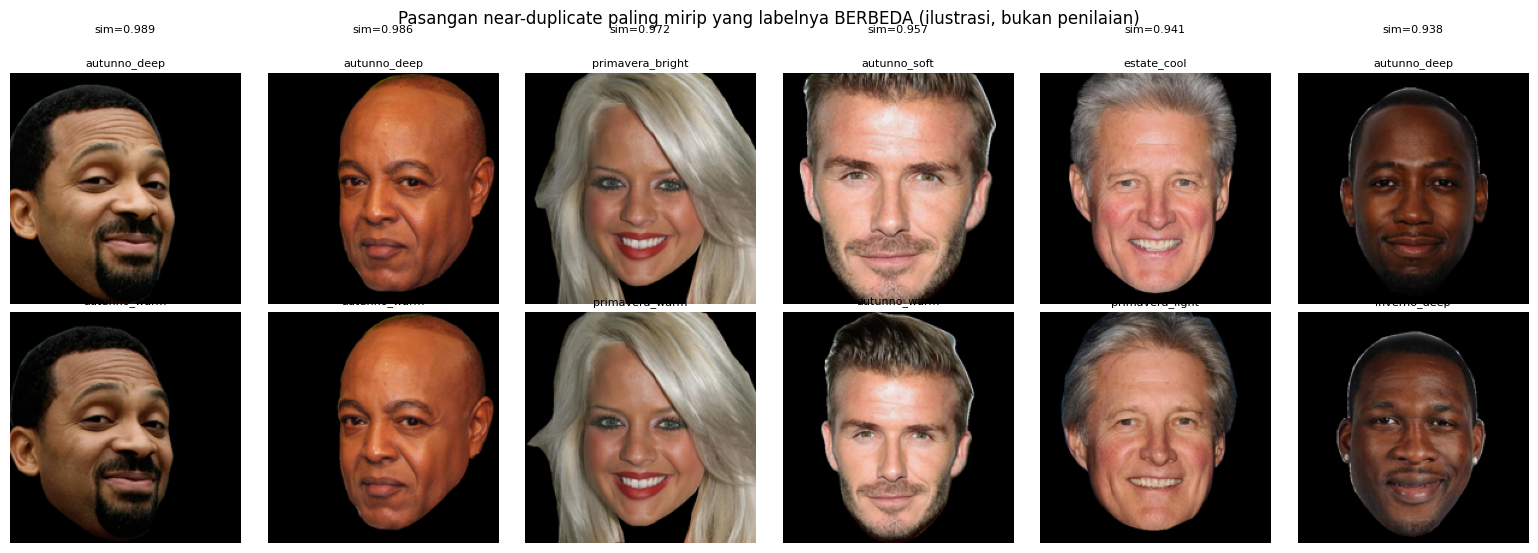

In [12]:
# ============================================================
# A.2 KONSISTENSI PASANGAN NEAR-DUPLICATE (berlaku juga untuk CelebA)
# ============================================================
pk = np.bincount(y_all, minlength=NUM_CLASSES) / N_ALL
chance_diff = 1 - float((pk ** 2).sum())
pairs = pd.DataFrame({"i": dup_i, "j": dup_j, "sim": dup_s})
pairs["label_i"], pairs["label_j"] = np.array(class_names)[y_all[dup_i]], np.array(class_names)[y_all[dup_j]]
pairs["beda_label"] = y_all[dup_i] != y_all[dup_j]
pairs["beda_season"] = season_of[y_all[dup_i]] != season_of[y_all[dup_j]]
pairs["celeba_keduanya"] = is_cel_all[dup_i] & is_cel_all[dup_j]
pairs["lintas_train_test"] = is_train[dup_i] != is_train[dup_j]

rows = []
for thr in DUP_LEVELS:
    p = pairs[pairs["sim"] >= thr]
    rows.append({"ambang_sim": thr, "n_pasangan": len(p), "beda_label": p["beda_label"].mean() if len(p) else np.nan,
                 "beda_season": p["beda_season"].mean() if len(p) else np.nan,
                 "n_celeba_keduanya": int(p["celeba_keduanya"].sum()),
                 "beda_label_celeba": p.loc[p["celeba_keduanya"], "beda_label"].mean() if p["celeba_keduanya"].any() else np.nan,
                 "n_lintas_train_test": int(p["lintas_train_test"].sum())})
dup_table = pd.DataFrame(rows)
display(dup_table.round(3))
print(f"Pembanding acak: dua gambar sembarang berbeda label dengan peluang {chance_diff:.1%}.")
print("Cara membaca: semakin tinggi ambang, semakin besar kemungkinan pasangan itu foto orang yang sama. "
      "Bila 'beda_label' di ambang tertinggi masih jauh di atas 0%, orang yang sama diberi label berbeda.")

conf = pairs[pairs["beda_label"]].sort_values("sim", ascending=False).head(6)
if len(conf):
    fig, axes = plt.subplots(2, len(conf), figsize=(2.6 * len(conf), 5.6), squeeze=False)
    for c, (_, r) in enumerate(conf.iterrows()):
        for rr, (idx, lab_) in enumerate(((r["i"], r["label_i"]), (r["j"], r["label_j"]))):
            with Image.open(df["resolved_path"].iloc[int(idx)]) as im:
                axes[rr, c].imshow(ImageOps.pad(im.convert("RGB"), (192, 192), color=(0, 0, 0)))
            axes[rr, c].set_title(lab_, fontsize=8); axes[rr, c].axis("off")
        axes[0, c].text(0.5, 1.18, f"sim={r['sim']:.3f}", transform=axes[0, c].transAxes, ha="center", fontsize=8)
    plt.suptitle("Pasangan near-duplicate paling mirip yang labelnya BERBEDA (ilustrasi, bukan penilaian)")
    plt.tight_layout(); plt.show()

## B. Label yang dicurigai (confident learning)

1. Model `emb_color_lr` (embedding DINOv3 ViT-S frozen + 87 fitur Lab, sama dengan E14) memberi probabilitas **out-of-fold** untuk setiap gambar official train (5 fold, dikelompokkan per orang). Gambar official test diprediksi oleh model yang dilatih di seluruh official train.
2. Ambang per kelas tₖ = rata-rata probabilitas kelas k pada gambar yang berlabel k (dari OOF train).
3. Sebuah gambar **dicurigai** bila ada kelas lain j dengan p(j) ≥ tⱼ, dan kelas itu yang paling yakin di antara kelas yang lolos ambang.

Model ini hanya ±32% akurat, jadi jumlah gambar yang dicurigai adalah **batas atas** noise label, bukan angka pasti. Kecurigaan yang lebih kuat: gambar yang dicurigai **dan** prediksi ensemble E14 setuju dengan kelas tersangka (hanya untuk official test, bila output E14 tersedia).

In [13]:
# ============================================================
# B.1 PROBABILITAS OUT-OF-FOLD emb_color_lr
# ============================================================
EMB_KEYS = ["cls_last", "mean_last"] + [f"mean_L{l}" for l in EXTRA_MEAN_LAYERS]
X_emb = np.hstack([EMB[k] for k in EMB_KEYS]).astype(np.float64)
_med = np.nanmedian(REG[train_rows], axis=0)
_med = np.where(np.isfinite(_med), _med, 0.0)
X_lab = np.hstack([np.where(np.isfinite(REG), REG, _med), (~np.isfinite(REG)).astype(np.float64)])
X_ec = np.hstack([X_emb, X_lab])

def make_lr(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))

def proba_full(model, X):
    out = np.zeros((len(X), NUM_CLASSES))
    out[:, model.classes_] = model.predict_proba(X)
    return out

t0 = time.time()
oof = np.zeros((len(train_rows), NUM_CLASSES))
for tr, va in folds:
    oof[va] = proba_full(make_lr(C_LR).fit(X_ec[train_rows[tr]], y_tr[tr]), X_ec[train_rows[va]])
base_model = make_lr(C_LR).fit(X_ec[train_rows], y_tr)
p_te = proba_full(base_model, X_ec[test_rows])
P_all = np.zeros((N_ALL, NUM_CLASSES))
P_all[train_rows], P_all[test_rows] = oof, p_te
ACC_BASE = float((p_te.argmax(1) == y_te).mean())
print(f"emb_color_lr | akurasi OOF train = {(oof.argmax(1) == y_tr).mean():.4f} | akurasi official test = {ACC_BASE:.4f} "
      f"(E14: {REFERENCE_TEST_ACC['E14 emb_color_lr']}) | {(time.time() - t0) / 60:.1f} menit")

emb_color_lr | akurasi OOF train = 0.3530 | akurasi official test = 0.3388 (E14: 0.318) | 1.3 menit


In [14]:
# ============================================================
# B.2 CONFIDENT LEARNING
# ============================================================
thr_k = np.array([oof[y_tr == k, k].mean() for k in range(NUM_CLASSES)])
above = P_all >= thr_k[None, :]
suspect = np.where(above, P_all, -1.0).argmax(1)
has = above.any(1)
suspect = np.where(has, suspect, y_all)
flag = has & (suspect != y_all)
p_label = P_all[np.arange(N_ALL), y_all]
p_susp = P_all[np.arange(N_ALL), suspect]
margin = np.where(flag, p_susp - p_label, -np.inf)          # makin besar = makin mencurigakan

print("Ambang per kelas t_k:", dict(zip(class_names, np.round(thr_k, 3))))
print(f"Dicurigai: official train {flag[train_rows].mean():.1%} ({int(flag[train_rows].sum())} gambar) | "
      f"official test {flag[test_rows].mean():.1%} ({int(flag[test_rows].sum())} gambar)")

strong = np.zeros(N_ALL, dtype=bool)
if E14_PRED is not None:
    strong[test_rows] = flag[test_rows] & (E14_PRED == suspect[test_rows])
    print(f"Official test yang dicurigai DAN ensemble E14 memilih kelas tersangka yang sama: "
          f"{int(strong[test_rows].sum())} gambar ({strong[test_rows].mean():.1%} dari official test)")

per_class = pd.DataFrame({
    "kelas": class_names,
    "n_train": np.bincount(y_tr, minlength=NUM_CLASSES),
    "dicurigai_train": [flag[train_rows][y_tr == k].mean() for k in range(NUM_CLASSES)],
    "n_test": np.bincount(y_te, minlength=NUM_CLASSES),
    "dicurigai_test": [flag[test_rows][y_te == k].mean() for k in range(NUM_CLASSES)],
    "t_k": thr_k,
}).sort_values("dicurigai_train", ascending=False).reset_index(drop=True)
display(per_class.round(3))

trans = pd.DataFrame({"label": np.array(class_names)[y_all[flag]], "tersangka": np.array(class_names)[suspect[flag]],
                      "partisi": np.where(is_train[flag], "train", "test")})
trans["season_sama"] = [a.split("_")[0] == b.split("_")[0] for a, b in zip(trans["label"], trans["tersangka"])]
top_trans = trans.groupby(["label", "tersangka", "season_sama"]).size().rename("jumlah").reset_index() \
                 .sort_values("jumlah", ascending=False).head(15).reset_index(drop=True)
display(top_trans)
print(f"Dari semua gambar yang dicurigai, {trans['season_sama'].mean():.1%} tersangkanya masih satu season dengan labelnya.")

Ambang per kelas t_k: {'autunno_deep': np.float64(0.311), 'autunno_soft': np.float64(0.134), 'autunno_warm': np.float64(0.151), 'estate_cool': np.float64(0.169), 'estate_light': np.float64(0.403), 'estate_soft': np.float64(0.261), 'inverno_bright': np.float64(0.18), 'inverno_cool': np.float64(0.169), 'inverno_deep': np.float64(0.303), 'primavera_bright': np.float64(0.115), 'primavera_light': np.float64(0.227), 'primavera_warm': np.float64(0.22)}
Dicurigai: official train 60.7% (2432 gambar) | official test 65.5% (597 gambar)


,kelas,n_train,dicurigai_train,n_test,dicurigai_test,t_k
0,primavera_bright,291,0.759,66,0.833,0.115
1,autunno_warm,283,0.703,74,0.662,0.151
2,inverno_bright,271,0.697,58,0.707,0.180
3,estate_cool,276,0.623,53,0.755,0.169
4,inverno_cool,345,0.623,89,0.584,0.169
5,primavera_warm,356,0.621,73,0.534,0.220
6,autunno_soft,318,0.610,73,0.712,0.134
7,inverno_deep,425,0.593,117,0.436,0.303
8,primavera_light,331,0.553,64,0.578,0.227
9,estate_soft,355,0.541,63,0.921,0.261


,label,tersangka,season_sama,jumlah
0,inverno_deep,autunno_deep,False,123
1,autunno_deep,inverno_deep,False,122
2,estate_light,primavera_light,False,96
3,inverno_deep,inverno_cool,True,91
4,inverno_cool,inverno_deep,True,75
5,estate_soft,primavera_light,False,65
6,autunno_warm,primavera_warm,False,65
7,primavera_warm,autunno_warm,False,61
8,inverno_bright,inverno_cool,True,57
9,primavera_light,estate_soft,False,57


Dari semua gambar yang dicurigai, 29.1% tersangkanya masih satu season dengan labelnya.


## C. Keterpisahan tiap pasangan sub-season

Untuk tiap pasangan kelas (a, b), classifier biner dilatih hanya pada gambar kelas a dan b (official train, fold yang sama dengan bagian B), lalu dihitung AUROC out-of-fold.

- **AUROC ≈ 0,5**: dari gambar, kedua kelas praktis tidak bisa dibedakan. Kesalahan di pasangan ini adalah batas data/label, bukan kelemahan model.
- **AUROC ≥ 0,8**: kelas mudah dibedakan; kesalahan di sini masih bisa diperbaiki model.

Dihitung dua kali: fitur **Lab saja** (warna kulit, rambut, mata, bibir, alis) dan **embedding + Lab**.

pasangan kelas:   0%|          | 0/66 [00:00<?, ?it/s]

Selesai dalam 1.7 menit.


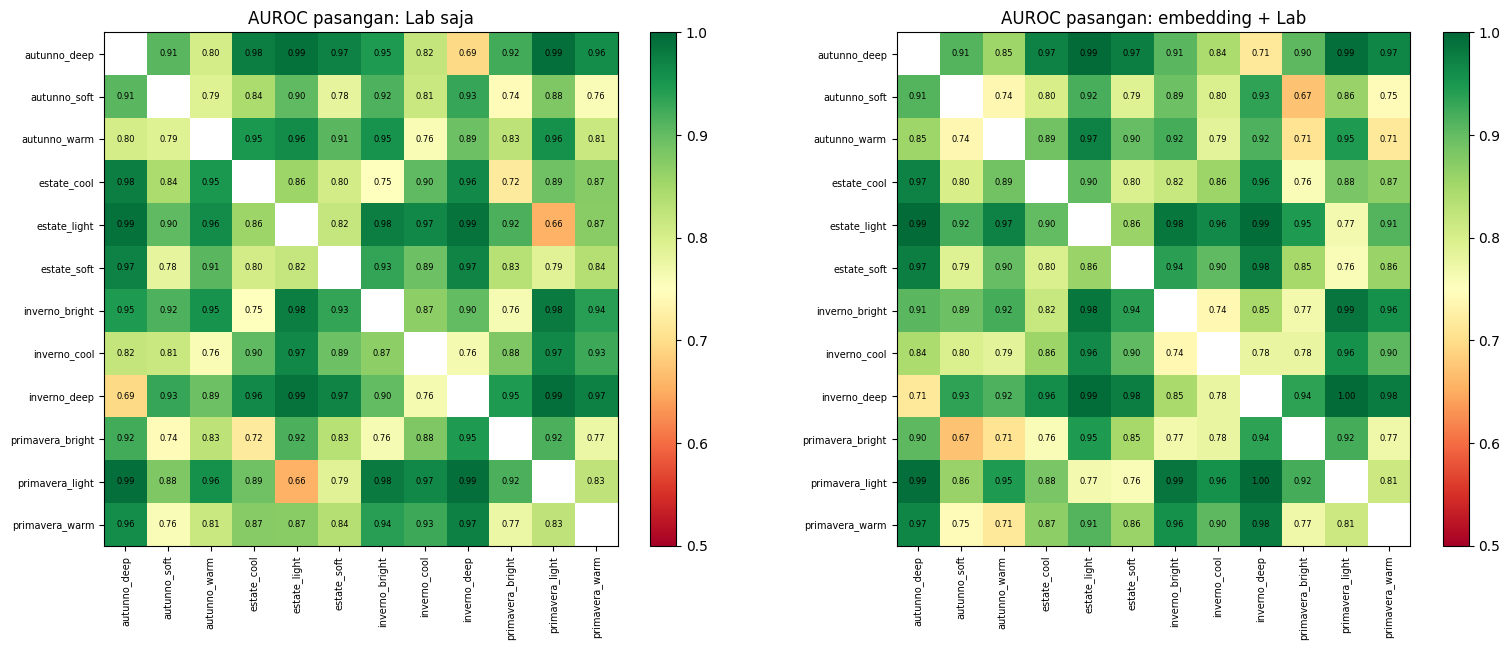

10 pasangan paling sulit dibedakan (embedding + Lab):


,kelas_a,kelas_b,season_sama,auroc_lab,auroc_emb_lab
0,autunno_soft,primavera_bright,False,0.744,0.671
1,autunno_warm,primavera_bright,False,0.826,0.709
2,autunno_deep,inverno_deep,False,0.693,0.714
3,autunno_warm,primavera_warm,False,0.815,0.715
4,autunno_soft,autunno_warm,True,0.792,0.737
5,inverno_bright,inverno_cool,True,0.868,0.740
6,autunno_soft,primavera_warm,False,0.757,0.745
7,estate_cool,primavera_bright,False,0.717,0.757
8,estate_soft,primavera_light,False,0.790,0.757
9,estate_light,primavera_light,False,0.655,0.765


Pasangan yang paling sering tertukar di E12-E14:


,pasangan,auroc_lab,auroc_emb_lab
0,autunno_deep vs inverno_deep,0.693,0.714
1,inverno_cool vs inverno_deep,0.762,0.779
2,estate_light vs primavera_light,0.655,0.765
3,autunno_warm vs primavera_warm,0.815,0.715
4,estate_soft vs estate_cool,0.805,0.798
5,estate_light vs estate_soft,0.819,0.859


Rata-rata AUROC semua pasangan | Lab: 0.879 | embedding + Lab: 0.873


In [15]:
# ============================================================
# C.1 AUROC BINER PER PASANGAN KELAS
# ============================================================
def pair_auc(X, a, b, C):
    scores, ys = [], []
    for tr, va in folds:
        trm, vam = tr[np.isin(y_tr[tr], [a, b])], va[np.isin(y_tr[va], [a, b])]
        if len(vam) == 0 or len(np.unique(y_tr[trm])) < 2:
            continue
        m = make_lr(C).fit(X[train_rows[trm]], (y_tr[trm] == b).astype(int))
        scores.append(m.predict_proba(X[train_rows[vam]])[:, 1]); ys.append((y_tr[vam] == b).astype(int))
    s, yy = np.concatenate(scores), np.concatenate(ys)
    return float(roc_auc_score(yy, s)) if len(np.unique(yy)) == 2 else np.nan

AUC_LAB = np.full((NUM_CLASSES, NUM_CLASSES), np.nan)
AUC_EC = np.full((NUM_CLASSES, NUM_CLASSES), np.nan)
t0 = time.time()
for a, b in tqdm(list(itertools.combinations(range(NUM_CLASSES), 2)), desc="pasangan kelas"):
    AUC_LAB[a, b] = AUC_LAB[b, a] = pair_auc(X_lab, a, b, C_LAB)
    AUC_EC[a, b] = AUC_EC[b, a] = pair_auc(X_ec, a, b, C_LR)
print(f"Selesai dalam {(time.time() - t0) / 60:.1f} menit.")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.6))
for ax, M, title in zip(axes, (AUC_LAB, AUC_EC), ("AUROC pasangan: Lab saja", "AUROC pasangan: embedding + Lab")):
    im = ax.imshow(M, cmap="RdYlGn", vmin=0.5, vmax=1.0)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(class_names, rotation=90, fontsize=7); ax.set_yticklabels(class_names, fontsize=7)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if i != j:
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=6)
    ax.set_title(title); plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.savefig(RESULT_DIR / "audit_pair_auroc.png", dpi=130); plt.show()

pair_df = pd.DataFrame([{"kelas_a": class_names[a], "kelas_b": class_names[b],
                         "season_sama": season_of[a] == season_of[b],
                         "auroc_lab": AUC_LAB[a, b], "auroc_emb_lab": AUC_EC[a, b]}
                        for a, b in itertools.combinations(range(NUM_CLASSES), 2)])
print("10 pasangan paling sulit dibedakan (embedding + Lab):")
display(pair_df.sort_values("auroc_emb_lab").head(10).round(3).reset_index(drop=True))
fp = pd.DataFrame([{"pasangan": f"{a} vs {b}", "auroc_lab": AUC_LAB[class2idx[a], class2idx[b]],
                    "auroc_emb_lab": AUC_EC[class2idx[a], class2idx[b]]} for a, b in FOCUS_PAIRS])
print("Pasangan yang paling sering tertukar di E12-E14:")
display(fp.round(3))
print(f"Rata-rata AUROC semua pasangan | Lab: {np.nanmean(pair_df['auroc_lab']):.3f} | embedding + Lab: {np.nanmean(pair_df['auroc_emb_lab']):.3f}")

## D. Dampak label yang dicurigai terhadap akurasi official test

`emb_color_lr` dilatih ulang di official train setelah membuang x% gambar latih yang **paling mencurigakan** (urut dari margin p(tersangka) − p(label)). Label official test tidak disentuh.

- Bila akurasi official test **naik** saat data mencurigakan dibuang, noise label di data latih memang menahan model; membersihkan atau memberi bobot rendah pada data itu layak dicoba di model utama.
- Bila akurasi **tidak berubah atau turun**, gambar yang dicurigai lebih mungkin kasus sulit yang sah, bukan label salah.

Kurva ini adalah **bukti audit**, bukan cara memilih model: jangan pilih x dari kurva ini lalu melaporkan angka test-nya sebagai hasil.

,buang_%,n_dibuang,acc_test,selisih,ci95_lo,ci95_hi
0,0.0,0,0.3388,0.0000,0.0000,0.0000
1,5.0,200,0.3268,-0.0121,-0.0263,0.0011
2,10.0,401,0.3268,-0.0121,-0.0296,0.0055
3,15.0,601,0.3147,-0.0241,-0.0439,-0.0055
4,20.0,802,0.3191,-0.0197,-0.0406,0.0000


Baris 0% = emb_color_lr tanpa pembersihan (0.3388). CI memuat 0 = tidak ada perubahan nyata.


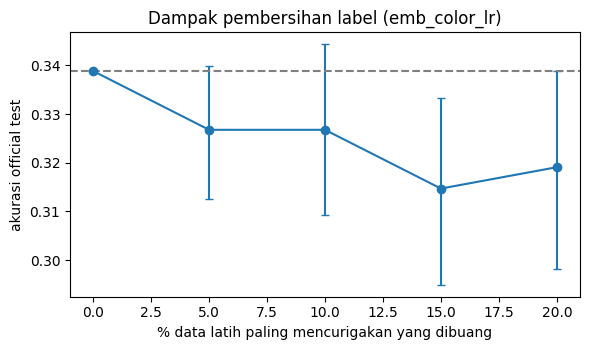

In [16]:
# ============================================================
# D.1 BUANG x% DATA LATIH PALING MENCURIGAKAN -> AKURASI OFFICIAL TEST
# ============================================================
def paired_boot(ok_a, ok_b, seed=SEED):
    rng = np.random.default_rng(seed)
    d = [ok_a[ix].mean() - ok_b[ix].mean() for ix in (rng.integers(0, len(ok_a), len(ok_a)) for _ in range(N_BOOT))]
    return float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

order = np.argsort(-margin[train_rows])                      # urut lokal train: paling mencurigakan dulu
n_flag_tr = int(flag[train_rows].sum())
ok_base = p_te.argmax(1) == y_te
rows = []
for frac in DROP_FRACS:
    n_drop = min(int(round(frac * len(train_rows))), n_flag_tr)
    keep = np.ones(len(train_rows), dtype=bool)
    keep[order[:n_drop]] = False
    m = base_model if n_drop == 0 else make_lr(C_LR).fit(X_ec[train_rows][keep], y_tr[keep])
    ok = proba_full(m, X_ec[test_rows]).argmax(1) == y_te
    lo, hi = paired_boot(ok, ok_base) if n_drop else (0.0, 0.0)
    rows.append({"buang_%": frac * 100, "n_dibuang": n_drop, "acc_test": ok.mean(), "selisih": ok.mean() - ACC_BASE,
                 "ci95_lo": lo, "ci95_hi": hi})
drop_df = pd.DataFrame(rows)
display(drop_df.round(4))
print(f"Baris 0% = emb_color_lr tanpa pembersihan ({ACC_BASE:.4f}). CI memuat 0 = tidak ada perubahan nyata.")
if n_flag_tr < round(max(DROP_FRACS) * len(train_rows)):
    print(f"Catatan: hanya {n_flag_tr} gambar latih yang dicurigai, jadi pembuangan dibatasi di jumlah itu.")

plt.figure(figsize=(6, 3.6))
plt.errorbar(drop_df["buang_%"], drop_df["acc_test"], yerr=[np.clip(drop_df["selisih"] - drop_df["ci95_lo"], 0, None), np.clip(drop_df["ci95_hi"] - drop_df["selisih"], 0, None)],
             fmt="o-", capsize=3)
plt.axhline(ACC_BASE, ls="--", color="gray")
plt.xlabel("% data latih paling mencurigakan yang dibuang"); plt.ylabel("akurasi official test")
plt.title("Dampak pembersihan label (emb_color_lr)"); plt.tight_layout()
plt.savefig(RESULT_DIR / "audit_drop_curve.png", dpi=130); plt.show()

## E. Ringkasan dan file keluaran

In [17]:
# ============================================================
# E.1 RINGKASAN + SIMPAN
# ============================================================
flags_df = pd.DataFrame({
    "path": rel_paths, "partisi": np.where(is_train, "train", "test"), "celeba": is_cel_all,
    "label": np.array(class_names)[y_all], "tersangka": np.array(class_names)[suspect],
    "dicurigai": flag, "dicurigai_kuat_E14": strong, "p_label": p_label, "p_tersangka": p_susp,
    "margin": np.where(flag, p_susp - p_label, np.nan),
})
flags_df[flags_df["dicurigai"]].sort_values("margin", ascending=False).to_csv(RESULT_DIR / "audit_label_dicurigai.csv", index=False)
pair_df.to_csv(RESULT_DIR / "audit_pair_auroc.csv", index=False)
dup_table.to_csv(RESULT_DIR / "audit_near_duplicate.csv", index=False)
person_df.to_csv(RESULT_DIR / "audit_per_orang.csv", index=False)
drop_df.to_csv(RESULT_DIR / "audit_drop_curve.csv", index=False)

fpi = {f"{a} vs {b}": round(float(AUC_EC[class2idx[a], class2idx[b]]), 3) for a, b in FOCUS_PAIRS}
summary = {
    "experiment_id": EXPERIMENT_ID,
    "A_orang_multi_label": f"{n_multi} dari {len(person_df)}",
    "A_near_dup_beda_label": {f">= {r.ambang_sim}": round(float(r.beda_label), 3) for r in dup_table.itertuples() if pd.notna(r.beda_label)},
    "A_pembanding_acak": round(chance_diff, 3),
    "B_dicurigai_train": round(float(flag[train_rows].mean()), 3),
    "B_dicurigai_test": round(float(flag[test_rows].mean()), 3),
    "B_dicurigai_kuat_test_E14": round(float(strong[test_rows].mean()), 3) if E14_PRED is not None else None,
    "C_auroc_rata2_lab": round(float(np.nanmean(pair_df["auroc_lab"])), 3),
    "C_auroc_rata2_emb_lab": round(float(np.nanmean(pair_df["auroc_emb_lab"])), 3),
    "C_auroc_pasangan_fokus": fpi,
    "D_acc_test_base": round(ACC_BASE, 4),
    "D_acc_test_per_buang": {f"{r['buang_%']:.0f}%": round(float(r["acc_test"]), 4) for _, r in drop_df.iterrows()},
}
(RESULT_DIR / "audit_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=float))
print(json.dumps(summary, indent=2, ensure_ascii=False, default=float))
print("\nFile tersimpan di", RESULT_DIR, ":", sorted(p.name for p in RESULT_DIR.iterdir()))

{
  "experiment_id": "AUDIT_LABEL_AFTER_E14",
  "A_orang_multi_label": "3 dari 175",
  "A_near_dup_beda_label": {
    ">= 0.9": 0.587,
    ">= 0.93": 0.478,
    ">= 0.95": 0.571,
    ">= 0.97": 0.75
  },
  "A_pembanding_acak": 0.914,
  "B_dicurigai_train": 0.607,
  "B_dicurigai_test": 0.655,
  "B_dicurigai_kuat_test_E14": null,
  "C_auroc_rata2_lab": 0.879,
  "C_auroc_rata2_emb_lab": 0.873,
  "C_auroc_pasangan_fokus": {
    "autunno_deep vs inverno_deep": 0.714,
    "inverno_cool vs inverno_deep": 0.779,
    "estate_light vs primavera_light": 0.765,
    "autunno_warm vs primavera_warm": 0.715,
    "estate_soft vs estate_cool": 0.798,
    "estate_light vs estate_soft": 0.859
  },
  "D_acc_test_base": 0.3388,
  "D_acc_test_per_buang": {
    "0%": 0.3388,
    "5%": 0.3268,
    "10%": 0.3268,
    "15%": 0.3147,
    "20%": 0.3191
  }
}

File tersimpan di /kaggle/working/AUDIT : ['audit_drop_curve.csv', 'audit_drop_curve.png', 'audit_label_dicurigai.csv', 'audit_near_duplicate.csv', 'audit_p

## Cara membaca hasil audit

| Temuan | Artinya | Langkah lanjut |
|---|---|---|
| A: pasangan near-duplicate (sim ≥ 0,95) sering beda label | Orang yang sama diberi label berbeda → noise label nyata | Laporkan sebagai batas dataset; pertimbangkan label lunak (soft label) |
| B: banyak gambar dicurigai, terkumpul di pasangan kelas tertentu | Pasangan itu ambigu di data latih | Bandingkan dengan C dan D sebelum menyimpulkan |
| C: AUROC pasangan fokus ≈ 0,5–0,65 | Pasangan itu hampir tidak bisa dibedakan dari gambar | Kesalahan di sana tidak akan hilang dengan arsitektur baru; tampilkan top-2 di produk |
| C: AUROC pasangan fokus ≥ 0,8 | Pasangan itu sebenarnya bisa dibedakan | Model utama belum memakai sinyalnya; perbaikan model masih masuk akal |
| D: akurasi naik nyata saat data dicurigai dibuang | Noise label di data latih menahan model | Terapkan pembersihan / pembobotan ke fine-tuning (E15) |
| D: akurasi tidak berubah | Data yang dicurigai = kasus sulit yang sah | Pembersihan label tidak akan membantu |

**Keterbatasan:** model audit hanya ±32% akurat, near-duplicate bukan identitas pasti, dan CelebA tidak punya identitas. Hasil audit adalah indikasi kuat atau lemah, bukan bukti bahwa label tertentu salah.